# Neural Network Classifier from Scratch

**Joey Shi**

This notebook goes over the mathematical details in a neural network used to predict hand-drawn digits.
We will be using the following conventions throughout:

* $X$ is the feature matrix, where each row $X_i$ is one example of a hand-drawn digit.
* $y$ is a vector labels, such that $y_i$ is the target label for example $X_i$.
* $p(y_i \mid \theta)$ is the probability of predicting $y_i$ given model parameters $\theta$.
* $\delta_{a, b} = 1$ if $a = b$ and $0$ otherwise.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import gzip
import pickle

# Load mnist data set of 26x26 hand-drawn digits
with gzip.open('../data/mnist.pkl.gz', 'rb') as f:
    train_set, valid_set, test_set = pickle.load(f, encoding="latin1")

X, y = train_set
X_test, y_test = test_set
examples, pixels = X.shape
print(f"Number of examples = {examples}, Image size = {pixels}")

Number of examples = 50000, Image size = 784


Label = 5


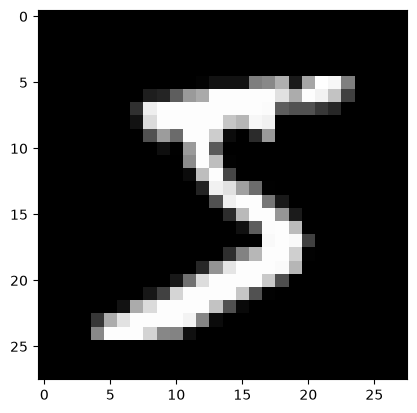

In [11]:
# Preview data
print(f"Label = {y[0]}")
image = np.reshape(X[0], (28, 28))
plt.imshow(image, cmap='gray')
plt.show()

## Defining the Prediction Model

We will focus on the inner workings of the [multilayer perceptron](https://en.wikipedia.org/wiki/Multilayer_perceptron) (MLP),
which is a type of neural network.

An MLP organizes a large number of its parameters (adjustable values used in computing predictions)
across multiple hidden layers. At each layer, we perform an affine transformation followed by applying a non-linear function.
The reason we have a non-linear function after an affine transform is because if we were to apply 2 affine transformations
in a row across 2 layers, that would be equivalent to a single affine transformation.
In other words, having 2 layers would've just been redundant.

**Proof.** Consider the affine transformations $T_1(x) = A_1x + b_1$ and $T_2(x) = A_2x + b_2$.
Then, $T_2(T_1(x)) = A_2(A_1x + b_1) + b_2 = (A_2A_1)x + (A_2b_1 + b_2)$ is another affine transform of $x$.

This model where the input data passes through each layer sequentially is called a *feedforward neural network*.
The ideal for this computational model is that picking the right parameters will allow
each node in a following layer to represent latent features in the examples itself.
An example would be if each node in a particular hidden layer represented the likelihood of certain
edges in a hand-drawn digit appearing.

> Note: 3b1b has a good video about the motivations behind this construction of a neural network if you want
> to build a stronger intuition https://www.youtube.com/watch?v=aircAruvnKk.

Let $h$ be an arbitrary non-linear function. We will refer to $h$ as the *activation function*.
Given an input example of a hand-drawn digit, we convert it into a vector $x$ and compute the following in the network:

$$
\begin{align*}
    a^{(0)} &= x & z^{(1)} &= W^{(1)}a^{(0)} + b^{(1)} \\
    a^{(1)} &= h\left(z^{(1)}\right) & z^{(2)} &= W^{(2)}a^{(1)} + b^{(2)} \\
    \vdots & & \vdots \\
    a^{(L-1)} &= h\left(z^{(L-1)}\right) & z^{(L)} &= W^{(L)}a^{(L-1)} + b^{(L)}.
\end{align*}
$$

> Note: we refer to $a^{(l)}, W^{(l)}, b^{(l)}$ as activations, weights and biases respectively. We want $z^{(L)}$ to be the same dimension as the number of possible label classes.
> Since we are just classifying hand-drawn digits, we choose the shapes of $W^{(L)}$ and $b^{(L)}$ to have $10$ rows so that $z^{(L)}\in\mathbb{R}^{10}$.

The last step in this process is to normalize $z^{(L)}$,
such that it becomes a valid probability distribution $p(z^{(L)})$, where $\sum_i [p(z^{(L)})]_i = 1$ and $p(z^{(L)}) \geq 0$.
This can be done by using the [Softmax function](https://en.wikipedia.org/wiki/Softmax_function),

$$
p_i = \text{softmax}(z^{(L)})_i = \frac{e^{z_i^{(L)}}}{\sum_j e^{z_j^{(L)}}}.
$$

The MLP chooses the digit with the highest probability as the final prediction. I.e., $\text{argmax}_i\,\, p_i$.

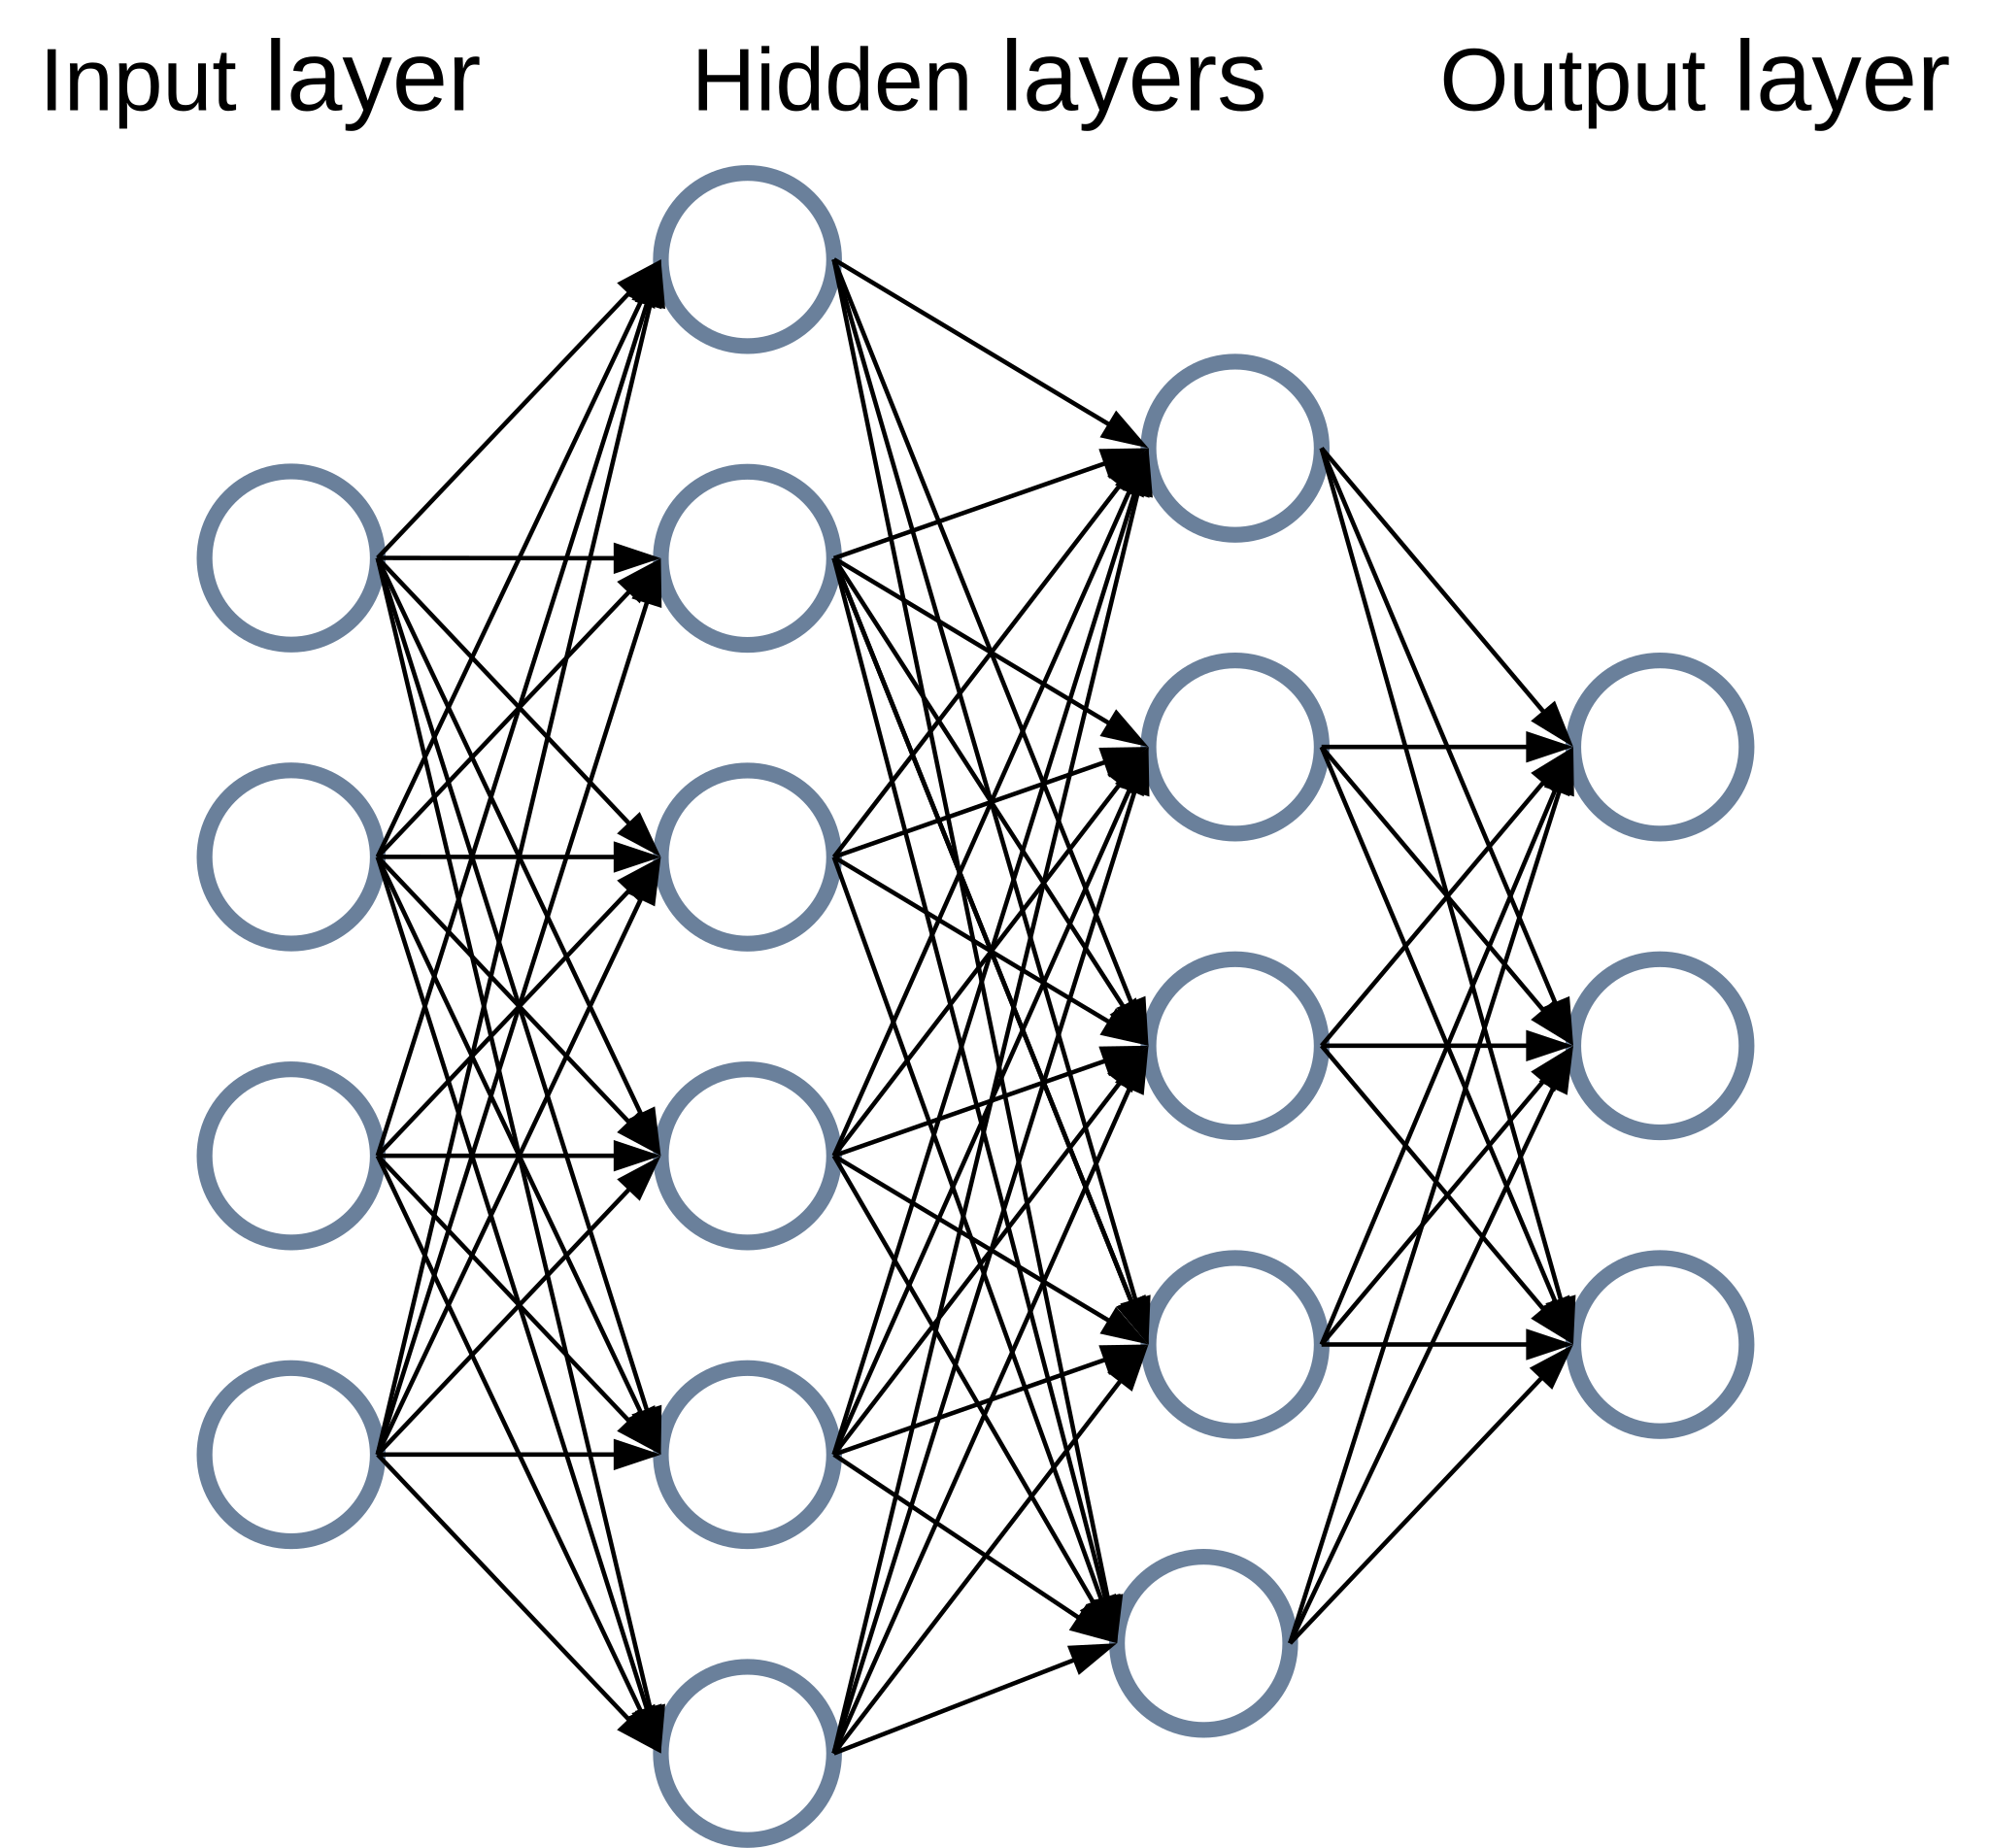

In [2]:
from IPython.display import SVG, display
display(SVG(filename="../images/neural_network.svg"))

## Training the Model

Initially, the model picks arbitrary weights and biases, so there's no guarentee that any of the predictions from the model will be accurate.
Hence, we need to measure how badly the model is doing on any given input example and also define an algorithm to adjust the parameters to minimize the loss.

Let ${y}$ be a [one-hot](https://en.wikipedia.org/wiki/One-hot) encoded target label. That is, $y[i] = 1$ if $i$ is the correct target label and $0$ otherwise.
For any target label, we want to maximum the probability $\vec{p}$ corresponding to the target label. This means the loss function for this network should behave oppositely.

The following loss function satisfies this requirement:

$$
C = -\sum_{i} y_i\log(p_i).
$$

> Note: the logarithm in the expression helps us avoid underflow issues when computing $\log(p)$.

$C$ is the cost for a single example, but for
multiple examples from the training data, we would
take the average loss across all examples.

To minimize this loss function, we can use
[gradient descent](https://en.wikipedia.org/wiki/Gradient_descent).

### Gradient descent overview

If we flattened all the parameters of the cost function
into a vector $\theta$, then $-\nabla_\theta C$ will have a direction in
the input space that would lead to the steepest descent in the loss.
So, to iteratively minimize the cost function, we
can use the following algorithm:

```
initialize theta
for i = 1...max_iters:
    compute gradient_theta
    theta -= alpha * gradient_theta
```

## Gradient Calculation

To visualize the relationships for all the values we calculate,
we will use a computational graph.

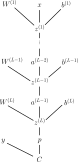

In [4]:
display(SVG(filename="../images/mlp_graph.svg"))

We define the following:

$$
\begin{align}
    \left[\frac{\partial C}{\partial W^{(l)}}\right]_{i,j} &= \frac{\partial C}{\partial w_{i,j}^{(l)}} &
    \left[\frac{\partial C}{\partial b}\right]_i = \frac{\partial C}{\partial b_i}.
\end{align}
$$

In each layer $l$, we need to evaluate $\displaystyle \frac{\partial C}{\partial W^{(l)}}$ and
$\displaystyle \frac{\partial C}{\partial b^{(l)}}$ to use them for gradient descent.
We begin with evaluating the partial derivative of $C$ with respect to a single weight from
the last layer $w = w_{i,j}^{(L)}$. By the chain rule,

$$
\begin{align}
    \frac{\partial C}{\partial w} = \sum_{m} \frac{\partial C}{\partial p_m}\frac{\partial p_m}{w}
    = \sum_{m}\sum_{k} \frac{\partial C}{\partial p_m}\frac{\partial p_m}{\partial z_k}\frac{\partial z_k}{\partial w}.
\end{align}
$$

We can evaluate each partial derivative factor separately:

$$
\begin{align}
    \frac{\partial C}{\partial p_m} &= -\frac{\partial}{\partial p_m} \sum_{i} y_i\log(p_i) = -\frac{y_m}{p_m}, \\
    \frac{\partial p_m}{\partial z_k} &= \frac{\partial}{\partial z_k} \text{softmax}(z)_m = p_m(\delta_{m,k} - p_m), \\
    \frac{\partial z_k}{\partial w} &= \frac{\partial}{\partial w} (W_k^{L}\cdot a^{(L - 1)} + b_k) = \delta_{i,k} a_j^{(L - 1)}.
\end{align}
$$

Then, we get the following:

$$
\begin{align}
    \frac{\partial C}{\partial w} &= \sum_{m}\sum_{k} -\frac{y_m}{p_m}\cdot p_m(\delta_{m,k} - p_k)\cdot \delta_{i,k} a_j^{(L - 1)} \\
    &= a_j^{(L - 1)}\sum_{m} y_{m}(p_i - \delta_{m,i}) \\
    &= a_j^{(L - 1)}(p_i - y_i) \\
    &= \left[(p - y)(a^{(L - 1)})^T\right]_{i,j} \\
    \frac{\partial C}{\partial W^{(L)}} &= (p - y)(a^{(L - 1)})^T.
\end{align}
$$

Similarly, we can discover $\displaystyle \frac{\partial C}{\partial b^{(L)}} = p - y$ and $\displaystyle \frac{\partial C}{\partial a^{(L - 1)}} = \left(W^{(L)}\right)^T(p - y)$.
As visualized in the computational graph, for any given layer $l$, we can compute the derivative with respect to $w = w_{i,j}^{(l)}$ using the chain rule as follows:

$$
\begin{align}
        \frac{\partial C}{\partial w} &= \sum_{m} \frac{\partial C}{\partial a_{m}^{(l)}}\cdot \frac{\partial a_{m}^{(l)}}{\partial z_{m}^{(l)}}\cdot \frac{\partial z_{m}^{(l)}}{\partial w} \\
        &= \sum_{m} \frac{\partial C}{\partial a_{m}^{(l)}}\cdot h'(z_{m})\cdot \delta_{m,i}a_{j}^{(l)} \\
        &= \frac{\partial C}{\partial a_{i}^{(l)}}\cdot h'(z_{i})\cdot a_{j}^{(l)} \\
        &= \left[\left(\frac{\partial C}{\partial a^{(l)}}\odot h'(z_{i})\right) \left(a^{(l)}\right)^T\right]_{i,j} \\
\end{align}
$$

# Computing the Gradient
Let $A^{(l)}$ be a matrix such that each row is an activation vector $a_i^{(l)}$ and let $Z^{(l)}$ be defined similarly.
Define a new matrix R by the recursion relation $R^{(l-1)} = R^{(l)}W^{(l)} \circ h\,'\left(Z^{(l-1)}\right)$ with a base case of $R^{(L)}$, where $r_{i, c}^{(L)} = p(y_i = c \mid D, x_i) - \delta_{y_i, c}$.
Then the derivatives of the weights and biases of our network are given by
$$
\frac{\partial f}{\partial W^{(l)}} = \left(R^{(l)}\right)^TA^{(l-1)} \hspace{1cm} \frac{\partial f}{\partial b^{(l)}} = \sum_{i=1}^{n} r_i^{(l)}
$$

**Gradient of $W^{(L)}$ and $b^{(L)}$**
\begin{align*}
    \frac{\partial f}{\partial w_{c,j}^{(L)}} &= \sum_{i=1}^{n} \left[-a_{i,j}^{(L-1)}\delta_{y_i, c} + \frac{1}{\sum_{c_0=1}^{k_l} \exp\left(z_{i,c_0}^{(L)}\right)}  \cdot \exp\left(z_{i,c}^{(L)}\right) \cdot a_{i,j}^{(L-1)}\right] &[\text{Chain Rule}] \\
    &= \sum_{i=1}^{n} [p(y_i = c \mid D, x_i) - \delta_{y_i,c}]a_{i,j}^{(L-1)} \\
    &= \sum_{i=1}^{n} r_{i,c}^{(L)}a_{i,j}^{(L-1)} \\
    \frac{\partial f}{\partial W^{(L)}} &= \left(R^{(L)}\right)^TA^{(L-1)} \\
    \frac{\partial f}{\partial b_{c}^{(L)}} &= \sum_{i=1}^{n} r_{i, c}^{(L)} \cdot 1 &[\text{Similar work as above}] \\
    \frac{\partial f}{\partial b^{(L)}} &= \sum_{i=1}^{n} r_i^{(L)}
\end{align*}

**Gradient of $W^{(L-1)}$ and $b^{(L-1)}$**
\begin{align*}
    \frac{\partial f}{\partial w_{j, k}^{(L-1)}} &= \sum_{i=1}^{n} \sum_{c=1}^{k_L} \left[p(y_i = c \mid D, x_i) - \delta_{y_i, c}\right] \cdot w_{c,j}^{(L)}  h\,'\left(z_{j, k}^{(L-1)}\right) \cdot a_{j, k}^{(L-2)} &[\text{Chain Rule}]\\
    &= \sum_{i=1}^{n} \sum_{c=1}^{k_L} r_{i,c}^{(L)} \cdot w_{c,k}^{(L)}h\,'\left(z_{i, k}^{(L-1)}\right) \cdot a_{i, k}^{(L-2)} \\
    &= \sum_{i=1}^{n} \left[\left(W^{(L)}\right)^T r_i^{(L)} \circ h\,'\left(z_{i}^{(L-1)}\right)\right] \cdot a_i^{(L-2)} \\
    &= \sum_{i=1}^{n} r_{i}^{(L-1)} \cdot a_i^{(L-2)} \\
    &= \left(R^{(L-1)}\right)^T A^{(L-2)} \\
    \frac{\partial f}{\partial b_{k}^{(L-1)}} &= \sum_{i=1}^{n} r_{i, k}^{(L-1)} \cdot 1 &[\text{Similar work as above}] \\
    \frac{\partial f}{\partial b^{(L-1)}} &= \sum_{i=1}^{n} r_i^{(L-1)}
\end{align*}

**The following derivations are trivial and left as an easy exercise for the reader**

In [ ]:
# Hyper parameters
hidden_layer_sizes = [100]
alpha = 0.001
batches = 10
epochs = 5

# Random initialization
weights = []
biases = []
layer_sizes = [X.shape[1]] + hidden_layer_sizes + [np.unique(y).size]
for i in range(1, len(layer_sizes)):
    weights.append(0.01 * np.random.randn(layer_sizes[i], layer_sizes[i - 1]))
    biases.append(0.01 * np.random.rand(layer_sizes[i]))

In [ ]:
def fun_obj(weights, biases):
    activations = [X]
    activation_derivs = []
    A = X
    Z = None
    for i, (W, b) in enumerate(zip(weights, biases)):
        Z = A @ W.T + b
        if i < len(weights) - 1:
            A = 1 / (1 + np.exp(-Z))
            activations.append(A)
            activation_derivs.append(A * (1 - A))

    f = softmax_loss(Z, y)
    G = np.exp(Z) / np.sum(np.exp(Z), axis=1)[:, None]
    for i, d in enumerate(y):
        G[i][d] -= 1

    grad_W = [None] * (len(layer_sizes) - 1)
    grad_b = [None] * (len(layer_sizes) - 1)

    grad_W[-1] = G.T @ activations[-1]
    grad_b[-1] = np.sum(G, axis=0)

    for i in range(len(layer_sizes) - 3, -1, -1):
        G = G @ weights[i + 1] * activation_derivs[i]
        grad_W[i] = G.T @ activations[i]
        grad_b[i] = np.sum(G, axis=0)

    return f, (grad_W, grad_b)

f, _ = fun_obj(weights, biases)
print(f"Initial loss = {f}")

# Stochastic Gradient Descent Algorithm

Define $D$ to be a vector containing all the weights and biases in our model. Then $f(D)$ is our loss function.
Given $E$ epoches, $B$ number of batches, and a learning rate $\alpha^t$, we proceed with minimizing $f(D)$ by stochastic gradient descent.
Randomly initialize $D^0$. For each epoch, for each batch, sample $\lfloor n / B \rfloor$ training examples without replacement and compute $\nabla f(D^{t})$. Then,
\begin{align*}
    D^{t+1} &= D^{t} - \alpha^t \nabla f(D^{t})
\end{align*}
We will use the parameters $D^E$ to make predictions for the model.

In [ ]:
for epoch in range(epochs):
    reordered_indices = np.random.choice(X.shape[0], size=X.shape[0], replace=False)
    for i in range(batches):
        batch = reordered_indices[i * X.shape[0] // batches: (i + 1) * X.shape[0] // batches]
        f, g = fun_obj(weights, biases)
        grad_W, grad_b = g
        for j, (W, gW) in enumerate(zip(weights, grad_W)):
            weights[j] -= alpha * gW
        for j, (b, gb) in enumerate(zip(biases, grad_b)):
            biases[j] -= alpha * gb
    print(f"Epoch: {epoch}, Loss: {f}")

In [ ]:
# Compute predictions y_hat
print([w.shape for w in weights])
print(X.shape)
Z = X
A = None
for W, b in zip(weights, biases):
    Z = Z @ W.T + b
    A = 1 / (1 + np.exp(-Z))
y_hat = np.argmax(Z, axis=1)

In [ ]:
i = 3
print(f"Predict: {y_hat[i]}, Actual: {y[i]}")
image = np.reshape(X[i], (28, 28))
plt.imshow(image, cmap='gray')
plt.show()